In [1]:
# ==========================================
# 1. General Utilities
# ==========================================
import os
import warnings
from pathlib import Path
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")
# ==========================================
# 2. Data Manipulation
# ==========================================
import pandas as pd
import numpy as np
# ==========================================
# 3. Data Visualization
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
# ==========================================
# 4. Database Connection
# ==========================================
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# ==========================================
# 5. Data Preprocessing
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# ==========================================
# 6. Machine Learning - Regression
# ==========================================
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    IsolationForest
)
# ==========================================
# 7. Machine Learning - Classification
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
# ==========================================
# 8. Model Evaluation
# ==========================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score)
# ==========================================
# 9. Anomaly Detection and Clustering
# ==========================================
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
# ==========================================
# 10. Model Saving and Loading
# ==========================================
import joblib
# ==========================================
# 11. FastAPI - Later, for API integration
# ==========================================
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
print("All SmartSpend AI libraries imported successfully!")

All SmartSpend AI libraries imported successfully!


In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# Find the project root containing .env
current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if (p / ".env").is_file()),
    None)
if project_root is None:
    raise FileNotFoundError(
        "Could not find .env. Open Jupyter from your project "
        "or update the .env path below.")
load_dotenv(project_root / ".env", override=False)
# Read database settings
database_url = os.getenv("DATABASE_URL")
if database_url:
    engine = create_engine(database_url, pool_pre_ping=True)
else:
    # Adjust these names if your .env uses different variable names.
    db_name = os.getenv("DB_NAME") or os.getenv("DB_DATABASE")
    db_user = os.getenv("DB_USER") or os.getenv("DB_USERNAME")
    db_password = os.getenv("DB_PASSWORD") or os.getenv("DB_PASS")
    db_host = os.getenv("DB_HOST", "localhost")
    db_port = os.getenv("DB_PORT", "5432")
    if not all([db_name, db_user, db_password]):
        raise ValueError(
            "Database settings missing. Check the variable names "
            "in your project's .env file.")
    db_url = URL.create(
        drivername="postgresql+psycopg2",
        username=db_user,
        password=db_password,
        host=db_host,
        port=int(db_port),
        database=db_name)
    engine = create_engine(db_url, pool_pre_ping=True)
# Test connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database(), version()"))
    database, version = result.fetchone()
print("PostgreSQL connected successfully!")
print("Database:", database)
print("Connection is ready for SmartSpend AI.")

PostgreSQL connected successfully!
Database: smart spend ai
Connection is ready for SmartSpend AI.


In [3]:
query = text("""
    SELECT
        id,
        user_id,
        category_id,
        amount,
        merchant,
        description,
        transaction_date
    FROM transactions
    WHERE transaction_type = 'expense'
    ORDER BY transaction_date;
""")
with engine.connect() as connection:
    forecast_df = pd.read_sql(query, connection)
forecast_df["transaction_date"] = pd.to_datetime(
    forecast_df["transaction_date"])
print("Expense records loaded:", len(forecast_df))
print("Number of users:", forecast_df["user_id"].nunique())
print("Date range:")
print(forecast_df["transaction_date"].min())
print(forecast_df["transaction_date"].max())
display(forecast_df.head())

Expense records loaded: 221
Number of users: 7
Date range:
2026-01-10 12:00:00+00:00
2026-10-12 00:00:00+00:00


,id,user_id,category_id,amount,merchant,description,transaction_date
0,205,7,9,1500.0,Demo bills,Demo bills expense 2026-01,2026-01-10 12:00:00+00:00
1,204,7,8,1000.0,Demo transport,Demo transport expense 2026-01,2026-01-10 12:00:00+00:00
2,203,7,7,1500.0,Demo food,Demo food expense 2026-01,2026-01-10 12:00:00+00:00
3,202,7,6,2400.0,Demo groceries,Demo groceries expense 2026-01,2026-01-10 12:00:00+00:00
4,210,7,14,7500.0,Demo rent,Demo rent expense 2026-01,2026-01-10 12:00:00+00:00


In [4]:
# Create a month column
forecast_df["month"] = (
    forecast_df["transaction_date"]
    .dt.to_period("M")
    .dt.to_timestamp())
# Calculate total expenses for each user in each month
monthly_expenses = (
    forecast_df
    .groupby(["user_id", "month"], as_index=False)["amount"]
    .sum()
    .rename(columns={"amount": "monthly_expense"})
    .sort_values(["user_id", "month"])
    .reset_index(drop=True))
print("Monthly expense records:", len(monthly_expenses))
display(monthly_expenses.head(27))

Monthly expense records: 27


,user_id,month,monthly_expense
0,1,2026-10-01,250.0
1,2,2026-10-01,370.0
2,3,2026-10-01,370.0
3,4,2026-01-01,15300.0
4,4,2026-02-01,15400.0
5,4,2026-03-01,15500.0
6,4,2026-04-01,15400.0
7,4,2026-05-01,15600.0
8,4,2026-06-01,19400.0
9,5,2026-01-01,21300.0


In [5]:
print("Months of data available per user:")
display(
    monthly_expenses
    .groupby("user_id")
    .agg(
        months_available=("month", "nunique"),
        first_month=("month", "min"),
        last_month=("month", "max"),
        average_monthly_expense=("monthly_expense", "mean")).round(2).reset_index())

Months of data available per user:


,user_id,months_available,first_month,last_month,average_monthly_expense
0,1,1,2026-10-01,2026-10-01,250.00
1,2,1,2026-10-01,2026-10-01,370.00
2,3,1,2026-10-01,2026-10-01,370.00
3,4,6,2026-01-01,2026-06-01,16100.00
4,5,6,2026-01-01,2026-06-01,21450.00
5,6,6,2026-01-01,2026-06-01,13841.67
6,7,6,2026-01-01,2026-06-01,17750.00


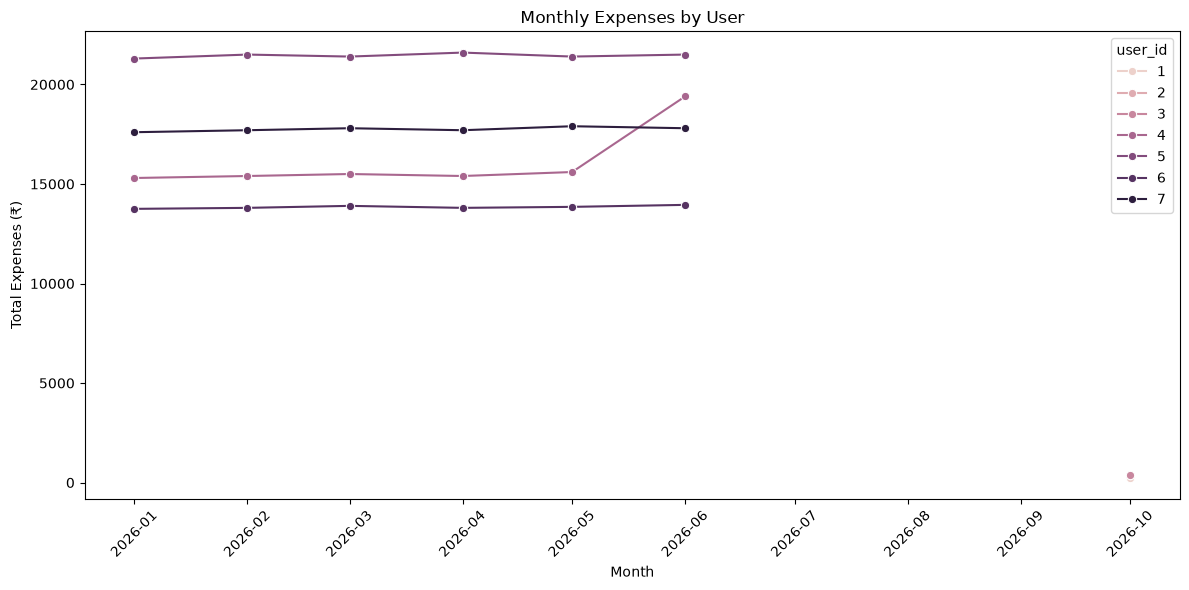

In [6]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_expenses,
    x="month",
    y="monthly_expense",
    hue="user_id",
    marker="o")
plt.title("Monthly Expenses by User")
plt.xlabel("Month")
plt.ylabel("Total Expenses (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
monthly_expenses = monthly_expenses.sort_values(
    ["user_id", "month"]).copy()
monthly_expenses["previous_month_expense"] = (
    monthly_expenses.groupby("user_id")["monthly_expense"].shift(1))
monthly_expenses["expense_change"] = (
    monthly_expenses["monthly_expense"]
    - monthly_expenses["previous_month_expense"])
monthly_expenses["expense_change_pct"] = (
    monthly_expenses["expense_change"]
    / monthly_expenses["previous_month_expense"]
    * 100)
display(
    monthly_expenses[
        [
            "user_id",
            "month",
            "monthly_expense",
            "previous_month_expense",
            "expense_change",
            "expense_change_pct"]].round(2))

,user_id,month,monthly_expense,previous_month_expense,expense_change,expense_change_pct
0,1,2026-10-01,250.0,NaN,NaN,NaN
1,2,2026-10-01,370.0,NaN,NaN,NaN
2,3,2026-10-01,370.0,NaN,NaN,NaN
3,4,2026-01-01,15300.0,NaN,NaN,NaN
4,4,2026-02-01,15400.0,15300.0,100.0,0.65
5,4,2026-03-01,15500.0,15400.0,100.0,0.65
6,4,2026-04-01,15400.0,15500.0,-100.0,-0.65
7,4,2026-05-01,15600.0,15400.0,200.0,1.30
8,4,2026-06-01,19400.0,15600.0,3800.0,24.36
9,5,2026-01-01,21300.0,NaN,NaN,NaN


In [8]:
# Forecast next month's expenses using the last 3 recorded months
forecast_results = []
for user_id, group in monthly_expenses.groupby("user_id"):
    group = group.sort_values("month")
    recent_expenses = group["monthly_expense"].tail(3)
    if len(recent_expenses) < 3:
        continue
    forecast_value = recent_expenses.mean()
    last_month = group["month"].max()
    next_month = last_month + pd.offsets.MonthBegin(1)
    forecast_results.append({
        "user_id": user_id,
        "last_recorded_month": last_month,
        "forecast_month": next_month,
        "last_3_month_average": round(forecast_value, 2),
        "forecast_expense": round(forecast_value, 2)})
forecast_results_df = pd.DataFrame(forecast_results)
display(forecast_results_df)

,user_id,last_recorded_month,forecast_month,last_3_month_average,forecast_expense
0,4,2026-06-01,2026-07-01,16800.00,16800.00
1,5,2026-06-01,2026-07-01,21500.00,21500.00
2,6,2026-06-01,2026-07-01,13866.67,13866.67
3,7,2026-06-01,2026-07-01,17800.00,17800.00


In [9]:
# Inspect the actual monthly history for every user
for user_id, group in monthly_expenses.groupby("user_id"):
    group = group.sort_values("month")
    print(f"\nUser ID: {user_id}")
    print("Number of recorded months:", len(group))
    display(
        group[["month", "monthly_expense"]].reset_index(drop=True))


User ID: 1
Number of recorded months: 1


,month,monthly_expense
0,2026-10-01,250.0



User ID: 2
Number of recorded months: 1


,month,monthly_expense
0,2026-10-01,370.0



User ID: 3
Number of recorded months: 1


,month,monthly_expense
0,2026-10-01,370.0


... (4 outputs left out)


User ID: 6
Number of recorded months: 6


,month,monthly_expense
0,2026-01-01,13750.0
1,2026-02-01,13800.0
2,2026-03-01,13900.0
3,2026-04-01,13800.0
4,2026-05-01,13850.0
5,2026-06-01,13950.0



User ID: 7
Number of recorded months: 6


,month,monthly_expense
0,2026-01-01,17600.0
1,2026-02-01,17700.0
2,2026-03-01,17800.0
3,2026-04-01,17700.0
4,2026-05-01,17900.0
5,2026-06-01,17800.0


In [10]:
for user_id, group in monthly_expenses.groupby("user_id"):
    months = group["month"].sort_values()
    expected_months = pd.date_range(
        start=months.min(),
        end=months.max(),
        freq="MS")
    missing_months = expected_months.difference(months)
    print(f"\nUser ID: {user_id}")
    print("Recorded months:", len(months))
    print("Missing months:", list(missing_months.strftime("%Y-%m")))


User ID: 1
Recorded months: 1
Missing months: []

User ID: 2
Recorded months: 1
Missing months: []

User ID: 3
Recorded months: 1
Missing months: []

User ID: 4
Recorded months: 6
Missing months: []

User ID: 5
Recorded months: 6
Missing months: []

User ID: 6
Recorded months: 6
Missing months: []

User ID: 7
Recorded months: 6
Missing months: []


In [11]:
# Evaluate the 3-month-average baseline using walk-forward validation
evaluation_results = []
for user_id, group in monthly_expenses.groupby("user_id"):
    group = group.sort_values("month").reset_index(drop=True)
    # Need at least 4 months to evaluate a forecast
    if len(group) < 4:
        continue
    for i in range(3, len(group)):
        actual_expense = group.loc[i, "monthly_expense"]

        predicted_expense = (
            group.loc[i-3:i-1, "monthly_expense"].mean())
        evaluation_results.append({
            "user_id": user_id,
            "forecast_month": group.loc[i, "month"],
            "predicted_expense": round(predicted_expense, 2),
            "actual_expense": actual_expense,
            "absolute_error": round(
                abs(actual_expense - predicted_expense), 2)})
evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)
if not evaluation_df.empty:
    mae = mean_absolute_error(
        evaluation_df["actual_expense"],
        evaluation_df["predicted_expense"])
    rmse = np.sqrt(
        mean_squared_error(
            evaluation_df["actual_expense"],
            evaluation_df["predicted_expense"]))
    print(f"Mean Absolute Error (MAE): ₹{mae:.2f}")
    print(f"Root Mean Squared Error (RMSE): ₹{rmse:.2f}")

,user_id,forecast_month,predicted_expense,actual_expense,absolute_error
0,4,2026-04-01,15400.00,15400.0,0.00
1,4,2026-05-01,15433.33,15600.0,166.67
2,4,2026-06-01,15500.00,19400.0,3900.00
3,5,2026-04-01,21400.00,21600.0,200.00
4,5,2026-05-01,21500.00,21400.0,100.00
5,5,2026-06-01,21466.67,21500.0,33.33
6,6,2026-04-01,13816.67,13800.0,16.67
7,6,2026-05-01,13833.33,13850.0,16.67
8,6,2026-06-01,13850.00,13950.0,100.00
9,7,2026-04-01,17700.00,17700.0,0.00


Mean Absolute Error (MAE): ₹391.67
Root Mean Squared Error (RMSE): ₹1130.16


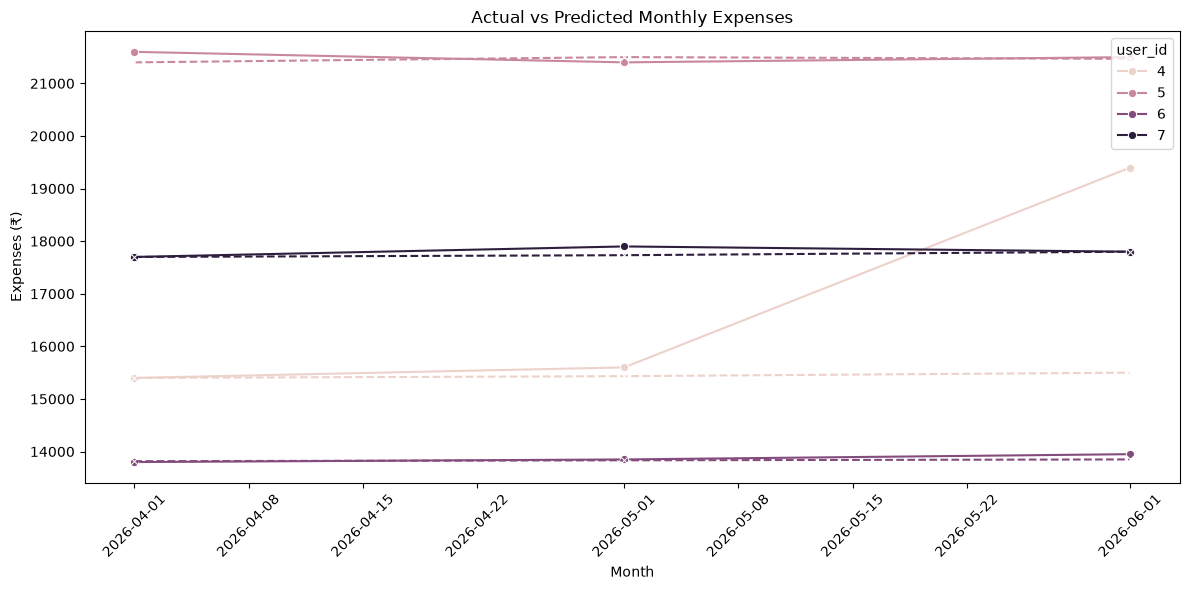

In [12]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=evaluation_df,
    x="forecast_month",
    y="actual_expense",
    hue="user_id",
    marker="o",
    linestyle="-"
)

sns.lineplot(
    data=evaluation_df,
    x="forecast_month",
    y="predicted_expense",
    hue="user_id",
    marker="x",
    linestyle="--",
    legend=False
)

plt.title("Actual vs Predicted Monthly Expenses")
plt.xlabel("Month")
plt.ylabel("Expenses (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:
from pathlib import Path
project_root = Path.cwd()
while project_root != project_root.parent:
    if (project_root / "src" / "expense_forecasting.py").exists():
        break
    project_root = project_root.parent
forecast_file = project_root / "src" / "expense_forecasting.py"
if forecast_file.exists():
    print("SUCCESS: expense_forecasting.py exists!")
    print("File location:", forecast_file)
else:
    print("ERROR: File not found. Check your VS Code folder.")

SUCCESS: expense_forecasting.py exists!
File location: C:\Users\Rudraksha\Desktop\secret\smart spend ai\python-engine\src\expense_forecasting.py


In [14]:
import sys
src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from expense_forecasting import forecast_monthly_expenses
print("SUCCESS: Forecasting function imported!")

SUCCESS: Forecasting function imported!


In [15]:
saved_forecast_df = forecast_monthly_expenses(
    monthly_expenses,
    window=3)
display(saved_forecast_df)

,user_id,forecast_month,forecast_expense,history_months_used
0,4,2026-07-01,16800.00,3
1,5,2026-07-01,21500.00,3
2,6,2026-07-01,13866.67,3
3,7,2026-07-01,17800.00,3
